# Verifying signed release artefacts

Use a public key to verify a release manifest and report which objects match it.

An Ed25519 signer signs exact manifest bytes. A consumer verifies the signature using an independently trusted public key before relying on the manifest hashes. This example generates a demonstration key in memory.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from cryptography.hazmat.primitives.asymmetric.ed25519 import Ed25519PrivateKey
from cryptography.exceptions import InvalidSignature
from hashlib import sha256
import json

## Run the local experiment

All records used below belong to the small fixture supplied by the example.

signature checks {'Original': True, 'Other key': False, 'Newline added': False}
matching files 2


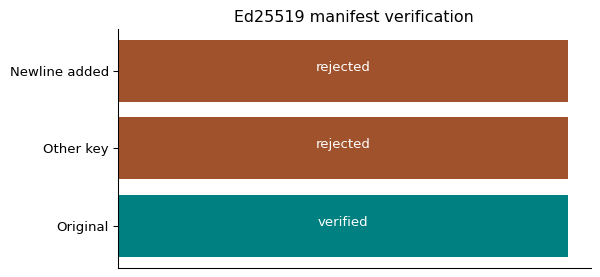

In [2]:
files = {"guide.txt": b"release 1", "table.csv": b"a,b"}
manifest = json.dumps(
    {k: sha256(v).hexdigest() for k, v in files.items()}, sort_keys=True, separators=(",", ":")
).encode()
signer = Ed25519PrivateKey.generate()
public = signer.public_key()
sig = signer.sign(manifest)


def verified(key, message):
    try:
        key.verify(sig, message)
        return True
    except InvalidSignature:
        return False


cases = {
    "Original": verified(public, manifest),
    "Other key": verified(Ed25519PrivateKey.generate().public_key(), manifest),
    "Newline added": verified(public, manifest + b"\n"),
}
assert list(cases.values()) == [True, False, False]
expected = json.loads(manifest)
print("signature checks", cases)
print("matching files", sum(sha256(v).hexdigest() == expected[k] for k, v in files.items()))
fig, ax = plt.subplots(figsize=(6.2, 2.8), constrained_layout=True)
ax.barh(list(cases), [1] * 3, color=["teal" if v else "sienna" for v in cases.values()])
[
    ax.text(0.5, i, "verified" if v else "rejected", ha="center", color="white")
    for i, v in enumerate(cases.values())
]
ax.set(xticks=[], title="Ed25519 manifest verification")
plt.show()

## Interpreting the result

The public key must be provisioned through a trusted route. A different serialisation changes the signed message even when the decoded fields look similar.

## Exercise

Sign a second version and verify that each signature matches only its own manifest.

## References

[RFC 8032, Edwards-curve digital signature algorithm](https://www.rfc-editor.org/rfc/rfc8032)

[Cryptography, Ed25519 signatures](https://cryptography.io/en/latest/hazmat/primitives/asymmetric/ed25519/)